In [39]:
import os
import re
import pandas as pd
from pypdf import PdfReader
from google.colab import files

PDF_FILES = [
    "Online Juli.pdf",
    "Online Agustus.pdf",
    "Online September.pdf",
    "Online Oktober.pdf",
]
available_pdfs = [f for f in PDF_FILES if os.path.exists(f)]
if not available_pdfs:
    available_pdfs = sorted([f for f in os.listdir(".") if f.lower().endswith(".pdf")])

print("Memproses semua file:", available_pdfs)

DATE_RE = re.compile(r"\b\d{1,2}[/-]\d{1,2}[/-]\d{2,4}\b")
RESI_RE = re.compile(r"\b(?:SPXID[A-Z0-9]+|SHPE[A-Z0-9]+|ID\d+[A-Z0-9]*|JT\d+|J[XY]\d+|S\d{9,}[A-Z0-9]*|\d{10,20})\b")
MARK_TOKEN_RE = re.compile(r"(?:[129]|[Π☐✔✓Vv]+)")

SKIP_PHRASES = [
    "LAPORAN PENJUALAN",
    "DATA PENJUALAN",
    "DATA BARANG",
    "DATA AWAL",
    "BARANG MASUK",
    "STOCK AKHIR",
    "NOMOR RESI",
    "NAMA PEMBELI",
    "TIPE MOTOR",
    "NAMA BARANG",
    "KODE BARANG",
    "TOTAL BARANG",
    "TOTAL ORDER",
    "JUMLAH BARANG",
    "MONCONG",
    "SARANGAN",
    "TIPE KNALPOT",
    "BRACKET",
    "TAMENG",
]

def token_is_active(tok: str) -> bool:
    t = tok.strip()
    if not t:
        return False
    if t in {"1", "2", "", "", "", "Π", "☐", "✔", "✓", "V", "v"}:
        return True
    try:
        return int(t) > 0
    except ValueError:
        return False

def parse_qty_val(tok: str):
    t = tok.strip()
    if t in {"1", "", "", "Π", "☐", "✔", "✓", "V", "v"}:
        return 1
    if t in {"2", ""}:
        return 2
    try:
        v = int(t)
        return v if v > 0 else None
    except ValueError:
        return None

def detect_header_x(lines):
    sh_x, ki_x = None, None
    for ln in lines:
        u = ln.upper()
        if "SHIJIRO" in u and "KINOCHI" in u:
            sh_x = u.find("SHIJIRO")
            ki_x = u.find("KINOCHI")
            break
    return sh_x, ki_x

def is_header_or_summary(line_upper: str, has_resi: bool) -> bool:
    if has_resi:
        return False
    if line_upper.strip() in {"SHIJIRO", "KINOCHI", "FULL", "SARTENG", "SARFULL", "1", "2", "SS", "PLASTIK"}:
        return True
    if any(k in line_upper for k in SKIP_PHRASES):
        return True
    tokens = line_upper.split()
    if len(tokens) >= 5 and sum(t == "0" for t in tokens) >= 4:
        return True
    return False

rows = []

for pdf_name in available_pdfs:
    reader = PdfReader(pdf_name)
    platform = ""
    is_retur = False
    current_date = ""
    last_sh_x, last_ki_x = None, None

    for page in reader.pages:
        layout_txt = page.extract_text(extraction_mode="layout") or ""
        lines = [ln.rstrip("\r\n") for ln in layout_txt.splitlines() if ln.strip()]

        sh_x, ki_x = detect_header_x(lines)
        if sh_x is not None and ki_x is not None:
            last_sh_x, last_ki_x = sh_x, ki_x
        else:
            sh_x, ki_x = last_sh_x, last_ki_x

        for ln in lines:
            stripped = ln.strip()
            up = stripped.upper()

            if "RETUR" in up and len(up) <= 45:
                is_retur = True
                platform = "Retur"
                continue
            if "OFFLINE" in up and len(up) <= 50:
                is_retur = False
                platform = "Offline"
                continue
            if "TIKTOK" in up and len(up) <= 50:
                is_retur = False
                platform = "TikTok"
                continue
            if "SHOPEE" in up and len(up) <= 50:
                is_retur = False
                platform = "Shopee"
                continue
            if "DATA BARANG KELUAR" in up and "ONLINE" in up:
                is_retur = False
                platform = "Online"
                continue

            m_date = DATE_RE.search(ln)
            if m_date:
                current_date = m_date.group(0)

            m_resi = RESI_RE.search(ln)
            has_resi = m_resi is not None

            if is_header_or_summary(up, has_resi):
                continue

            marks_all = list(MARK_TOKEN_RE.finditer(ln))
            if not has_resi and not marks_all:
                continue

            resi = m_resi.group(0) if has_resi else ""
            start_search = m_resi.end() if has_resi else 0

            right_marks = [
                m for m in MARK_TOKEN_RE.finditer(ln, pos=start_search)
                if m.start() >= (sh_x - 8 if sh_x is not None else start_search + 10)
            ]
            if not right_marks:
                right_marks = [m for m in MARK_TOKEN_RE.finditer(ln, pos=start_search)][-2:]

            has_sh = False
            has_ki = False
            qty_val = None

            if right_marks:
                if sh_x is not None and ki_x is not None:
                    mid_sh_ki = (sh_x + ki_x) / 2.0
                    ki_end_bound = ki_x + max(len("KINOCHI"), 10)
                    for m in right_marks:
                        pos_x = m.start()
                        tok_str = m.group(0)
                        if token_is_active(tok_str):
                            if (sh_x - 8) <= pos_x < mid_sh_ki:
                                has_sh = True
                            elif mid_sh_ki <= pos_x <= ki_end_bound:
                                has_ki = True

                qty_val = parse_qty_val(right_marks[-1].group(0))
                first_right_x = right_marks[0].start()
                left_slice = ln[start_search:first_right_x]
            else:
                left_slice = ln[start_search:]

            chunks = [c.strip() for c in re.split(r"\s{2,}|\t", left_slice) if c.strip()]
            if chunks and re.fullmatch(r"\d{1,3}", chunks[0]):
                chunks = chunks[1:]

            if len(chunks) >= 2 and re.fullmatch(r"[A-Z0-9]{2,8}", chunks[0]):
                tipe_motor = chunks[1]
            elif len(chunks) >= 1:
                tipe_motor = chunks[0]
            else:
                tipe_motor = ""

            jenis_parts = []
            if has_sh and has_ki:
                jenis_parts.append("Shijiro Kinochi")
            elif has_sh:
                jenis_parts.append("Shijiro")
            elif has_ki:
                jenis_parts.append("Kinochi")

            upper_row = ln.upper()
            for seri in ["VORTEX", "LUSTER", "METALICA", "MOONLIGHT", "KOU", "SUNBLUE"]:
                if seri in upper_row:
                    seri_title = seri.title()
                    if seri_title not in " ".join(jenis_parts):
                        jenis_parts.append(seri_title)

            if not jenis_parts:
                if "SARFULL" in upper_row:
                    jenis_parts.append("Sarfull")
                elif "SARTENG" in upper_row:
                    jenis_parts.append("Sarteng")

            jenis_knalpot = " ".join(jenis_parts) if jenis_parts else ""

            if is_retur:
                keterangan = "Retur"
                qty_aktual = 0
            else:
                keterangan = "Selesai"
                qty_aktual = qty_val if qty_val is not None else ""

            rows.append({
                "No": len(rows) + 1,
                "Tanggal": current_date if current_date else "",
                "Platform": platform if platform else "",
                "Nomor Resi": resi,
                "Jenis Knalpot": jenis_knalpot,
                "Tipe Motor": tipe_motor,
                "Qty": qty_val if qty_val is not None else "",
                "Qty Aktual": qty_aktual,
                "Keterangan": keterangan,
            })

df_all = pd.DataFrame(rows, columns=[
    "No",
    "Tanggal",
    "Platform",
    "Nomor Resi",
    "Jenis Knalpot",
    "Tipe Motor",
    "Qty",
    "Qty Aktual",
    "Keterangan",
])

print("Total semua baris:", len(df_all))
print("\nRincian per Platform:")
print(df_all["Platform"].value_counts(dropna=False))
display(df_all.head(25))

out_csv = "rekap_ndr_lengkap.csv"
df_all.to_csv(out_csv, index=False, encoding="utf-8-sig")
files.download(out_csv)

Memproses semua file: ['Online Juli.pdf', 'Online Agustus.pdf', 'Online September.pdf', 'Online Oktober.pdf']
Total semua baris: 2324

Rincian per Platform:
Platform
Shopee     835
           682
TikTok     530
Retur      153
Offline    124
Name: count, dtype: int64


,No,Tanggal,Platform,Nomor Resi,Jenis Knalpot,Tipe Motor,Qty,Qty Aktual,Keterangan
0,1,,TikTok,JX9837457654,Shijiro,GF,1,1,Selesai
1,2,,TikTok,570489471876,Shijiro,FAZZIO,1,1,Selesai
2,3,,TikTok,570489482696,Shijiro,M3,1,1,Selesai
3,4,,TikTok,JX9837758573,Shijiro,STYLO,1,1,Selesai
4,5,,TikTok,JX9834598373,Shijiro,M GT 115,1,1,Selesai
5,6,1/7/2026,TikTok,570488468384,Shijiro,BN,1,1,Selesai
6,7,1/7/2026,TikTok,570488414169,Shijiro,PCX 150,1,1,Selesai
7,8,1/7/2026,TikTok,JX9836167079,Shijiro,SN,1,1,Selesai
8,9,1/7/2026,TikTok,570489013282,Shijiro,GF,1,1,Selesai
9,10,1/7/2026,TikTok,JY1079200590,Shijiro,NEX 2,1,1,Selesai


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# === BAB 2: MEMAHAMI DATA (INSPEKSI AWAL, MISSING VALUE, DUPLIKASI & KATEGORI) ===
import pandas as pd
import numpy as np

CSV_PATH = "rekap_ndr_lengkap.csv"
df_raw = pd.read_csv(CSV_PATH, dtype=str)

# Ubah string kosong / spasi saja menjadi NaN untuk audit kualitas data di tahap analisis
df = df_raw.apply(
    lambda col: col.str.strip().replace({"": np.nan, "nan": np.nan, "None": np.nan})
    if col.dtype == "object" else col
)

print("Dimensi dataset (Baris, Kolom):", df.shape)
print("\nTipe data awal:")
print(df.dtypes)

audit_awal = pd.DataFrame({
    "Jumlah_Kosong": df.isna().sum(),
    "Persen_Kosong (%)": (df.isna().mean() * 100).round(2),
    "Jumlah_Unik": df.nunique(dropna=True),
})
print("\n=== Ringkasan Missing Value & Nilai Unik ===")
display(audit_awal)

print("Duplikat baris identik (semua kolom):", df.duplicated().sum())
print("Duplikat baris (tanpa kolom 'No'):", df.drop(columns=["No"], errors="ignore").duplicated().sum())

if "Nomor Resi" in df.columns:
    resi_valid = df["Nomor Resi"].dropna()
    print(f"Nomor Resi terisi: {len(resi_valid)} | Resi unik: {resi_valid.nunique()}")

for col in ["Platform", "Jenis Knalpot", "Tipe Motor", "Keterangan"]:
    if col in df.columns:
        print(f"\n-- Top 10 {col} --")
        print(df[col].value_counts(dropna=False).head(10))

Dimensi dataset (Baris, Kolom): (2324, 9)

Tipe data awal:
No               object
Tanggal          object
Platform         object
Nomor Resi       object
Jenis Knalpot    object
Tipe Motor       object
Qty              object
Qty Aktual       object
Keterangan       object
dtype: object

=== Ringkasan Missing Value & Nilai Unik ===


,Jumlah_Kosong,Persen_Kosong (%),Jumlah_Unik
No,0,0.00,2324
Tanggal,64,2.75,112
Platform,682,29.35,4
Nomor Resi,192,8.26,2003
Jenis Knalpot,169,7.27,14
Tipe Motor,27,1.16,234
Qty,3,0.13,3
Qty Aktual,3,0.13,4
Keterangan,0,0.00,2


Duplikat baris identik (semua kolom): 0
Duplikat baris (tanpa kolom 'No'): 52
Nomor Resi terisi: 2132 | Resi unik: 2003

-- Top 10 Platform --
Platform
Shopee     835
NaN        682
TikTok     530
Retur      153
Offline    124
Name: count, dtype: int64

-- Top 10 Jenis Knalpot --
Jenis Knalpot
Shijiro             1790
Kinochi              261
NaN                  169
Vortex                27
Shijiro Kinochi       20
Sarteng               15
Sarfull                8
Shijiro Metalica       8
Metalica               6
Kou                    5
Name: count, dtype: int64

-- Top 10 Tipe Motor --
Tipe Motor
BN            113
             112
M3            101
SN             94
NEX 2          81
BO             81
BK             72
VN             57
MS             54
SCOOPY NEW     51
Name: count, dtype: int64

-- Top 10 Keterangan --
Keterangan
Selesai    2171
Retur       153
Name: count, dtype: int64


=== BAB 3: MEMUAT & MEMERIKSA DATA ===
Dimensi df_raw: (2324, 9) (Baris, Kolom)
Daftar Kolom: ['No', 'Tanggal', 'Platform', 'Nomor Resi', 'Jenis Knalpot', 'Tipe Motor', 'Qty', 'Qty Aktual', 'Keterangan']


,No,Tanggal,Platform,Nomor Resi,Jenis Knalpot,Tipe Motor,Qty,Qty Aktual,Keterangan
0,1,NaN,TikTok,JX9837457654,Shijiro,GF,1,1,Selesai
1,2,NaN,TikTok,570489471876,Shijiro,FAZZIO,1,1,Selesai
2,3,NaN,TikTok,570489482696,Shijiro,M3,1,1,Selesai
3,4,NaN,TikTok,JX9837758573,Shijiro,STYLO,1,1,Selesai
4,5,NaN,TikTok,JX9834598373,Shijiro,M GT 115,1,1,Selesai



--- Tipe Data df_raw ---
No               object
Tanggal          object
Platform         object
Nomor Resi       object
Jenis Knalpot    object
Tipe Motor       object
Qty              object
Qty Aktual       object
Keterangan       object
dtype: object


,count,unique,top,freq
No,2324,2324,1,1
Tanggal,2260,112,12/10/2026,60
Platform,1642,4,Shopee,835
Nomor Resi,2132,2003,SPXID06279931961A,4
Jenis Knalpot,2155,14,Shijiro,1790
Tipe Motor,2297,234,BN,113
Qty,2321,3,1,2234
Qty Aktual,2321,4,1,2082
Keterangan,2324,2,Selesai,2171


/tmp/ipykernel_5259/1401136827.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=dtype_counts.values, y=dtype_counts.index, ax=ax1, palette='Set2')
/tmp/ipykernel_5259/1401136827.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=plat_raw.values, y=plat_raw.index, ax=ax2, palette='Blues_d')


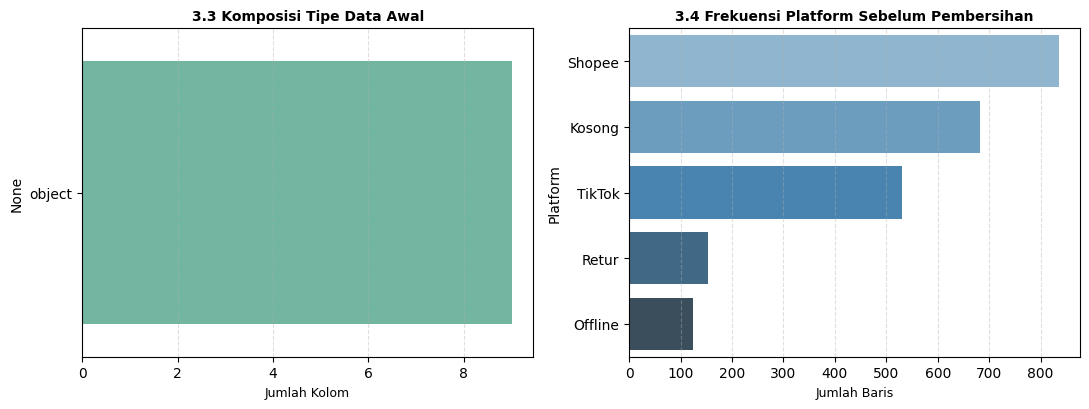

In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# Asumsikan df_raw sudah dimuat sebelumnya (misal: pd.read_csv("..."))
# 3.1 & 3.2 Inspeksi Dimensi, Kolom, dan Baris Awal
print("=== BAB 3: MEMUAT & MEMERIKSA DATA ===")
print(f"Dimensi df_raw: {df_raw.shape} (Baris, Kolom)")
print("Daftar Kolom:", df_raw.columns.tolist())
display(df_raw.head(5))

# 3.3 Pemeriksaan Tipe Data
print("\n--- Tipe Data df_raw ---")
print(df_raw.dtypes)

# 3.4 Ringkasan Statistik Awal Numerik & Kategorikal
display(df_raw.describe(include='all').T)

# Visualisasi Bab 3: Komposisi Tipe Data & Top 10 Kategori Awal
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2), dpi=100)

dtype_counts = df_raw.dtypes.astype(str).value_counts()
sns.barplot(x=dtype_counts.values, y=dtype_counts.index, ax=ax1, palette='Set2')
ax1.set_title("3.3 Komposisi Tipe Data Awal", fontweight='bold', fontsize=10)
ax1.set_xlabel("Jumlah Kolom", fontsize=9)
ax1.grid(axis='x', linestyle='--', alpha=0.4)

if 'Platform' in df_raw.columns:
    plat_raw = df_raw['Platform'].fillna('Kosong').value_counts()
    sns.barplot(x=plat_raw.values, y=plat_raw.index, ax=ax2, palette='Blues_d')
    ax2.set_title("3.4 Frekuensi Platform Sebelum Pembersihan", fontweight='bold', fontsize=10)
    ax2.set_xlabel("Jumlah Baris", fontsize=9)
    ax2.grid(axis='x', linestyle='--', alpha=0.4)
else:
    ax2.axis('off')

plt.tight_layout()
plt.show()

=== BAB 4: PENANGANAN MISSING VALUES & PEMBERSIHAN DATA ===
--- Tabel Missing Values Sebelum Pembersihan ---


,Missing_Sebelum,Persen_Sebelum (%)
Platform,682,29.35
Nomor Resi,192,8.26
Jenis Knalpot,169,7.27
Tanggal,64,2.75
Tipe Motor,27,1.16
Qty,3,0.13
Qty Aktual,3,0.13


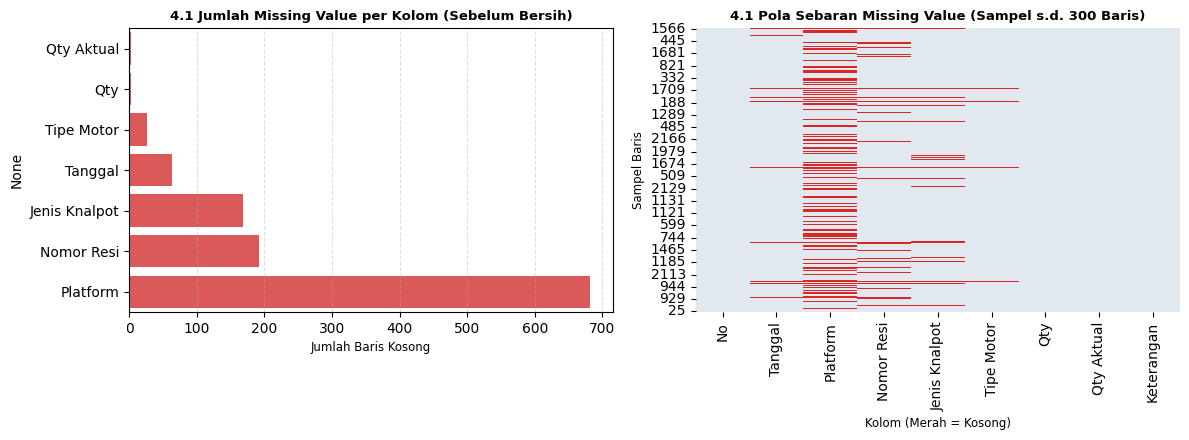

,Transaksi,Total_Qty,Total_Qty_Aktual,Total_Return
Bulan,,,,
2026-07,503,511.0,470.0,41
2026-08,478,487.0,464.0,23
2026-09,553,575.0,537.0,37
2026-10,790,901.0,849.0,52


In [36]:
print("=== BAB 4: PENANGANAN MISSING VALUES & PEMBERSIHAN DATA ===")
df = df_raw.copy()

# 4.1 Identifikasi Missing Values SEBELUM pembersihan
miss_before = df.isnull().sum()
miss_pct_before = (miss_before / len(df) * 100).round(2)
miss_table = pd.DataFrame({
    'Missing_Sebelum': miss_before,
    'Persen_Sebelum (%)': miss_pct_before
})
print("--- Tabel Missing Values Sebelum Pembersihan ---")
display(miss_table[miss_table['Missing_Sebelum'] > 0].sort_values(by='Missing_Sebelum', ascending=False))

# Visualisasi 4.1a: Barplot Missing Value per Kolom (Sebelum vs Sesudah)
df = df.apply(lambda c: c.str.strip().replace({'': np.nan, 'nan': np.nan, 'None': np.nan}) if c.dtype == 'object' else c)

# 1. Penanganan Tanggal & Koreksi Typo Admin
df['Tanggal_Dipulihkan'] = df['Tanggal']
df.loc[0:4, 'Tanggal_Dipulihkan'] = '1/7/2026'
df.loc[503:506, 'Tanggal_Dipulihkan'] = '1/8/2026'
df.loc[981:988, 'Tanggal_Dipulihkan'] = '2/9/2026'
df.loc[1534:1580, 'Tanggal_Dipulihkan'] = '1/10/2026'
df['Tanggal_Dipulihkan'] = df['Tanggal_Dipulihkan'].replace('15/01/2026', '15/10/2026')
df['Tanggal_dt'] = pd.to_datetime(df['Tanggal_Dipulihkan'], dayfirst=True, format='mixed')
df['Bulan'] = df['Tanggal_dt'].dt.strftime('%Y-%m')

# 2. Standardisasi Istilah
df['Platform'] = df['Platform'].replace({'Offline': 'WhatsApp', 'Retur': 'Return'})
df['Keterangan'] = df['Keterangan'].replace({'Retur': 'Return'})

# 3. Penanganan Nomor Resi
df['Ada_Resi'] = df['Nomor Resi'].notna().astype(int)
df['Nomor_Resi_Bersih'] = df['Nomor Resi'].fillna('TANPA_RESI')

# 4. Penanganan Platform (Imputasi Prefiks Resi)
def infer_platform(resi):
    if pd.isna(resi) or resi == 'TANPA_RESI':
        return 'Kosong'
    r = str(resi).strip().upper()
    if r.startswith(('SPXID', 'SHPE', 'S06', '201')):
        return 'Shopee'
    if r.startswith(('570', '520', 'JY', 'JX', 'S570')):
        return 'TikTok'
    return 'Kosong'

df['Platform_Imputasi'] = df['Platform']
mask_plat_null = df['Platform'].isna()
df.loc[mask_plat_null, 'Platform_Imputasi'] = df.loc[mask_plat_null, 'Nomor Resi'].apply(infer_platform)
df['Platform_Imputasi'] = df['Platform_Imputasi'].fillna('Kosong')

# 5. Penanganan Produk & Kategori
def classify_product(row):
    jk = str(row['Jenis Knalpot']).strip().title() if pd.notna(row['Jenis Knalpot']) else ''
    tm = str(row['Tipe Motor']).strip().upper() if pd.notna(row['Tipe Motor']) else ''
    aksesori = ['TAMENG', 'TUTUP', 'BAUT', 'SARANGAN', 'SARTENG', 'SARFULL', 'SARBOR']
    if any(k in jk.upper() for k in aksesori) or any(k in tm for k in aksesori):
        return pd.Series(['Aksesori', jk if jk else 'Aksesori'])
    elif jk != '':
        return pd.Series(['Knalpot', jk])
    else:
        if 'MET' in tm:
            return pd.Series(['Knalpot', 'Metalica'])
        if 'VER' in tm or 'VERTEX' in tm or 'VORTEX' in tm:
            return pd.Series(['Knalpot', 'Vortex'])
        return pd.Series(['Kosong', 'Kosong'])

df[['Kategori_Produk', 'Jenis_Knalpot_Bersih']] = df.apply(classify_product, axis=1)

# 6. Penanganan Tipe Motor
df['Tipe_Motor_Bersih'] = (
    df['Tipe Motor'].astype(str)
    .str.replace('\uf020', '', regex=False)
    .str.strip().replace({'': np.nan, 'nan': np.nan, 'None': np.nan})
    .str.upper().fillna('KOSONG')
)

# 7. Penanganan Qty & Qty Aktual
df['Qty_num'] = pd.to_numeric(df['Qty'], errors='coerce').fillna(1.0)
df['Qty_Aktual_num'] = pd.to_numeric(df['Qty Aktual'], errors='coerce')
df.loc[df['Qty_Aktual_num'].isna() & (df['Keterangan'] == 'Selesai'), 'Qty_Aktual_num'] = 1.0
df.loc[df['Qty_Aktual_num'].isna() & (df['Keterangan'] == 'Return'), 'Qty_Aktual_num'] = 0.0

# 8. Pemulihan Kanal Asal Return
selesai_map = df[df['Keterangan'] == 'Selesai'].dropna(subset=['Nomor Resi']).drop_duplicates(subset=['Nomor Resi']).set_index('Nomor Resi')

def recover_return_channel(row):
    if row['Keterangan'] != 'Return':
        return row['Platform_Imputasi']
    resi = row['Nomor Resi']
    if pd.notna(resi) and resi in selesai_map.index:
        plat = selesai_map.loc[resi, 'Platform_Imputasi']
        if plat not in ['Return', 'Kosong']:
            return plat
    pred = infer_platform(resi)
    if pred != 'Kosong':
        return pred
    if pd.notna(resi) and str(resi).startswith(('ID', 'JT')):
        return 'Ekspedisi (J&T/Ninja)'
    return 'Return_Tanpa_Kanal'

df['Platform_Kanal_Asal'] = df.apply(recover_return_channel, axis=1)
df.to_csv("rekap_ndr_cleaned_v6.csv", index=False)

# Visualisasi Bab 4: Barplot Missing Value Sebelum Pembersihan & Heatmap Pola Missingness
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5), dpi=100)

miss_sorted = miss_before[miss_before > 0].sort_values(ascending=True)
if len(miss_sorted) > 0:
    sns.barplot(x=miss_sorted.values, y=miss_sorted.index, ax=ax1, color='#ef4444')
    ax1.set_title("4.1 Jumlah Missing Value per Kolom (Sebelum Bersih)", fontweight='bold', fontsize=9.5)
    ax1.set_xlabel("Jumlah Baris Kosong", fontsize=8.5)
    ax1.grid(axis='x', linestyle='--', alpha=0.4)
else:
    ax1.text(0.5, 0.5, "Tidak ada missing value", ha='center', va='center')
    ax1.set_title("4.1 Jumlah Missing Value per Kolom", fontweight='bold', fontsize=9.5)

# Pola missingness (sampling hingga 300 baris agar ringan & jelas)
sample_miss = df_raw.sample(min(len(df_raw), 300), random_state=42).isnull().astype(int)
sns.heatmap(sample_miss, cbar=False, cmap=['#e2e8f0', '#dc2626'], ax=ax2)
ax2.set_title("4.1 Pola Sebaran Missing Value (Sampel s.d. 300 Baris)", fontweight='bold', fontsize=9.5)
ax2.set_xlabel("Kolom (Merah = Kosong)", fontsize=8.5)
ax2.set_ylabel("Sampel Baris", fontsize=8.5)

plt.tight_layout()
plt.show()

# Rekap Distribusi 4 Bulan Kalender
display(df.groupby('Bulan').agg(
    Transaksi=('No', 'count'),
    Total_Qty=('Qty_num', 'sum'),
    Total_Qty_Aktual=('Qty_Aktual_num', 'sum'),
    Total_Return=('Keterangan', lambda x: (x == 'Return').sum())
))

=== BAB 5: EKSPLORASI KARAKTERISTIK DATA ===


,count,mean,std,min,25%,median,75%,max,skewness,kurtosis
Total_Qty,106.0,23.34,14.72,1.0,16.00,20.0,28.00,105.0,2.86,12.56
Total_Qty_Aktual,106.0,21.89,14.65,0.0,14.25,18.0,25.75,103.0,2.95,12.97
Transaksi,106.0,21.92,10.62,1.0,15.25,19.5,27.75,64.0,1.19,2.72
Return,106.0,1.44,1.97,0.0,0.00,1.0,2.75,9.0,1.66,2.94


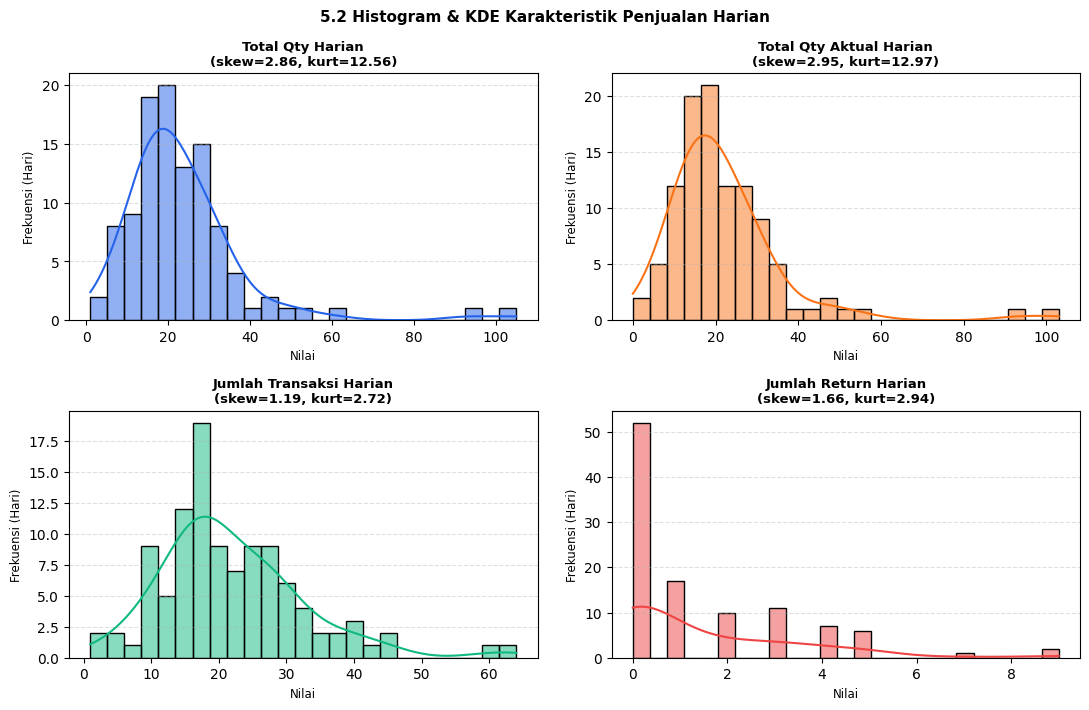

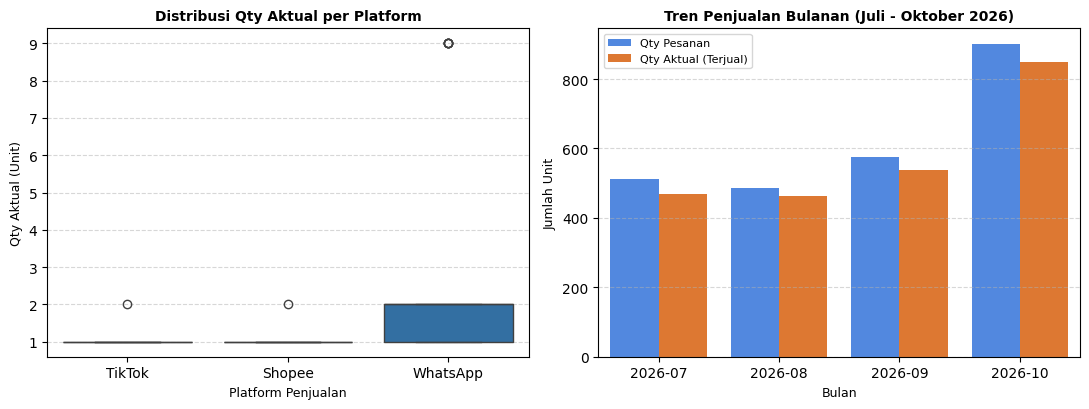

In [37]:
print("=== BAB 5: EKSPLORASI KARAKTERISTIK DATA ===")

# Agregasi Harian (Hari Aktif)
daily = df.groupby('Tanggal_dt').agg(
    Total_Qty=('Qty_num', 'sum'),
    Total_Qty_Aktual=('Qty_Aktual_num', 'sum'),
    Transaksi=('No', 'count'),
    Return=('Keterangan', lambda x: (x == 'Return').sum())
).reset_index()

# 5.1 Ringkasan Statistik Deskriptif Harian
desc_daily = daily[['Total_Qty', 'Total_Qty_Aktual', 'Transaksi', 'Return']].describe().T
desc_daily['median'] = daily[['Total_Qty', 'Total_Qty_Aktual', 'Transaksi', 'Return']].median()
desc_daily['skewness'] = daily[['Total_Qty', 'Total_Qty_Aktual', 'Transaksi', 'Return']].skew()
desc_daily['kurtosis'] = daily[['Total_Qty', 'Total_Qty_Aktual', 'Transaksi', 'Return']].kurt()
display(desc_daily[['count', 'mean', 'std', 'min', '25%', 'median', '75%', 'max', 'skewness', 'kurtosis']].round(2))

# 5.2 Visualisasi Histogram + KDE Variabel Numerik
fig, axes = plt.subplots(2, 2, figsize=(11, 7.2), dpi=100)
kde_items = [
    (daily['Total_Qty'], 'Total Qty Harian', axes[0, 0], '#2563eb'),
    (daily['Total_Qty_Aktual'], 'Total Qty Aktual Harian', axes[0, 1], '#f97316'),
    (daily['Transaksi'], 'Jumlah Transaksi Harian', axes[1, 0], '#10b981'),
    (daily['Return'], 'Jumlah Return Harian', axes[1, 1], '#ef4444'),
]

for s, judul, ax, warna in kde_items:
    sns.histplot(s, kde=True, ax=ax, color=warna, bins=25)
    ax.set_title(f"{judul}\n(skew={s.skew():.2f}, kurt={s.kurt():.2f})", fontweight='bold', fontsize=9.5)
    ax.set_xlabel("Nilai", fontsize=8.5)
    ax.set_ylabel("Frekuensi (Hari)", fontsize=8.5)
    ax.grid(axis='y', linestyle='--', alpha=0.4)

plt.suptitle("5.2 Histogram & KDE Karakteristik Penjualan Harian", fontweight='bold', fontsize=11)
plt.tight_layout()
plt.show()

# Visualisasi Gabungan Asli: Boxplot per Platform & Barplot Bulanan
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2), dpi=100)

plat_clean = df[df['Platform_Imputasi'].isin(['Shopee', 'TikTok', 'WhatsApp'])]
sns.boxplot(data=plat_clean, x='Platform_Imputasi', y='Qty_Aktual_num', ax=ax1,
            hue='Platform_Imputasi', palette='Blues', legend=False)
ax1.set_title('Distribusi Qty Aktual per Platform', fontweight='bold', fontsize=10)
ax1.set_xlabel('Platform Penjualan', fontsize=9)
ax1.set_ylabel('Qty Aktual (Unit)', fontsize=9)
ax1.grid(axis='y', linestyle='--', alpha=0.5)

monthly = df.groupby('Bulan')[['Qty_num', 'Qty_Aktual_num']].sum().reset_index()
monthly_melt = monthly.melt(id_vars='Bulan', value_vars=['Qty_num', 'Qty_Aktual_num'],
                            var_name='Metrik', value_name='Jumlah')
monthly_melt['Metrik'] = monthly_melt['Metrik'].replace({'Qty_num': 'Qty Pesanan', 'Qty_Aktual_num': 'Qty Aktual (Terjual)'})

sns.barplot(data=monthly_melt, x='Bulan', y='Jumlah', hue='Metrik', ax=ax2, palette=['#3b82f6', '#f97316'])
ax2.set_title('Tren Penjualan Bulanan (Juli - Oktober 2026)', fontweight='bold', fontsize=10)
ax2.set_xlabel('Bulan', fontsize=9)
ax2.set_ylabel('Jumlah Unit', fontsize=9)
ax2.legend(fontsize=8)
ax2.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

=== BAB 6: TRANSFORMASI DATA & PREPROCESSING ===


,Asli,log1p,sqrt
Total Qty Harian,2.86,-0.77,1.03
Total Qty Aktual Harian,2.95,-1.59,0.68


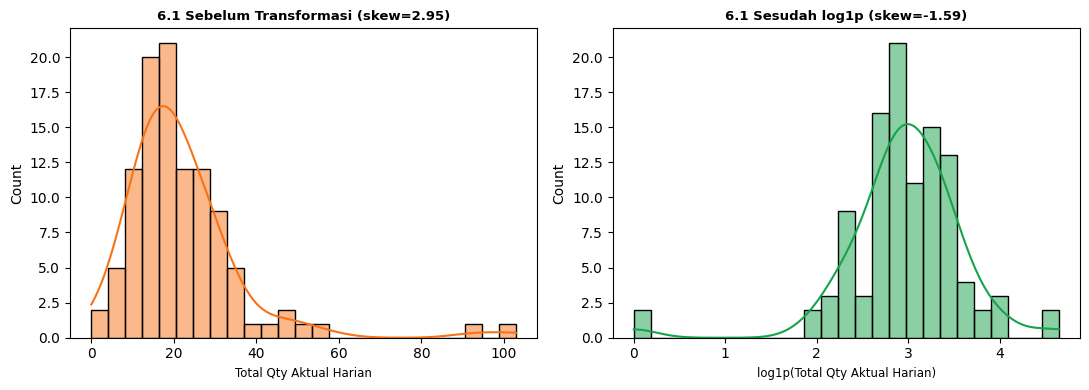

,Kondisi,Mean,Std,Min,Maks
0,Asli,21.89,14.65,0.0,103.00
1,Setelah StandardScaler,-0.00,1.00,-1.5,5.56
2,Setelah MinMaxScaler,0.21,0.14,0.0,1.00


Kolom Fitur Bebas Leakage: ['Plat_Kosong', 'Plat_Shopee', 'Plat_TikTok', 'Plat_WhatsApp']


,Plat_Kosong,Plat_Shopee,Plat_TikTok,Plat_WhatsApp
0,0,0,1,0
1,0,0,1,0
2,0,0,1,0
3,0,0,1,0
4,0,0,1,0


Data Latih (Juli - September 2026): 1534 baris transaksi.
Data Uji (Oktober 2026):           790 baris transaksi.


In [38]:
print("=== BAB 6: TRANSFORMASI DATA & PREPROCESSING ===")

# 6.1 Evaluasi Transformasi Distribusi
s_qty = daily['Total_Qty']
s_akt = daily['Total_Qty_Aktual']

tab_6_1 = pd.DataFrame({
    'Asli': [s_qty.skew(), s_akt.skew()],
    'log1p': [np.log1p(s_qty).skew(), np.log1p(s_akt).skew()],
    'sqrt': [np.sqrt(s_qty).skew(), np.sqrt(s_akt).skew()]
}, index=['Total Qty Harian', 'Total Qty Aktual Harian'])
display(tab_6_1.round(2))

# Visualisasi 6.1: Sebelum vs Sesudah log1p (Total Qty Aktual Harian)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4), dpi=100)
sns.histplot(s_akt, kde=True, ax=ax1, color='#f97316', bins=25)
ax1.set_title(f"6.1 Sebelum Transformasi (skew={s_akt.skew():.2f})", fontweight='bold', fontsize=9.5)
ax1.set_xlabel("Total Qty Aktual Harian", fontsize=8.5)

s_akt_log = np.log1p(s_akt)
sns.histplot(s_akt_log, kde=True, ax=ax2, color='#16a34a', bins=25)
ax2.set_title(f"6.1 Sesudah log1p (skew={s_akt_log.skew():.2f})", fontweight='bold', fontsize=9.5)
ax2.set_xlabel("log1p(Total Qty Aktual Harian)", fontsize=8.5)

plt.tight_layout()
plt.show()

# 6.2 Standarisasi & Normalisasi Skala
scaler_std = StandardScaler()
scaled_std = scaler_std.fit_transform(s_akt.values.reshape(-1, 1)).flatten()

scaler_mm = MinMaxScaler()
scaled_mm = scaler_mm.fit_transform(s_akt.values.reshape(-1, 1)).flatten()

tab_6_2 = pd.DataFrame([
    {'Kondisi': 'Asli', 'Mean': s_akt.mean(), 'Std': s_akt.std(), 'Min': s_akt.min(), 'Maks': s_akt.max()},
    {'Kondisi': 'Setelah StandardScaler', 'Mean': scaled_std.mean(), 'Std': scaled_std.std(ddof=0), 'Min': scaled_std.min(), 'Maks': scaled_std.max()},
    {'Kondisi': 'Setelah MinMaxScaler', 'Mean': scaled_mm.mean(), 'Std': scaled_mm.std(ddof=0), 'Min': scaled_mm.min(), 'Maks': scaled_mm.max()}
])
display(tab_6_2.round(2))

# 6.3 One-Hot Encoding Fitur (Bebas Leakage)
plat_clean_ohe = df['Platform_Imputasi'].replace({'Return': 'Kosong'})
df_plat_ohe = pd.get_dummies(plat_clean_ohe, prefix='Plat', dtype=int)
print("Kolom Fitur Bebas Leakage:", df_plat_ohe.columns.tolist())
display(df_plat_ohe.head(5))

# 6.4 Feature Engineering (Ekstraksi Waktu & Rasio Harian) + Pembagian Kronologis
daily['Hari_ke'] = (daily['Tanggal_dt'] - daily['Tanggal_dt'].min()).dt.days
daily['Nama_Hari'] = daily['Tanggal_dt'].dt.day_name()
daily['Is_Weekend'] = daily['Tanggal_dt'].dt.dayofweek.isin([5, 6]).astype(int)
daily['Rasio_Aktual_per_Transaksi'] = np.where(daily['Transaksi'] > 0, daily['Total_Qty_Aktual'] / daily['Transaksi'], 0.0)
daily['Rasio_Return_Harian'] = np.where(daily['Transaksi'] > 0, daily['Return'] / daily['Transaksi'], 0.0)

train_df = df[df['Tanggal_dt'] < '2026-10-01']
test_df = df[df['Tanggal_dt'] >= '2026-10-01']
print(f"Data Latih (Juli - September 2026): {len(train_df)} baris transaksi.")
print(f"Data Uji (Oktober 2026):           {len(test_df)} baris transaksi.")

=== BAB 7: VISUALISASI HUBUNGAN DATA ===


/tmp/ipykernel_5259/2617602149.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=kat_counts.values, y=kat_counts.index, ax=ax1, palette='viridis')
/tmp/ipykernel_5259/2617602149.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=ket_counts.values, y=ket_counts.index, ax=ax2, palette='magma')


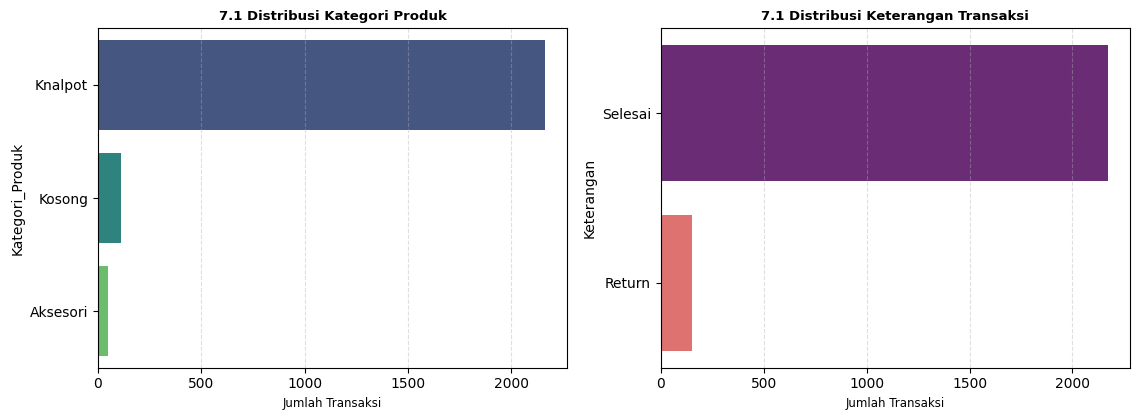

/tmp/ipykernel_5259/2617602149.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Kategori_Produk', y='Qty_Aktual_num', ax=ax2, palette='pastel')


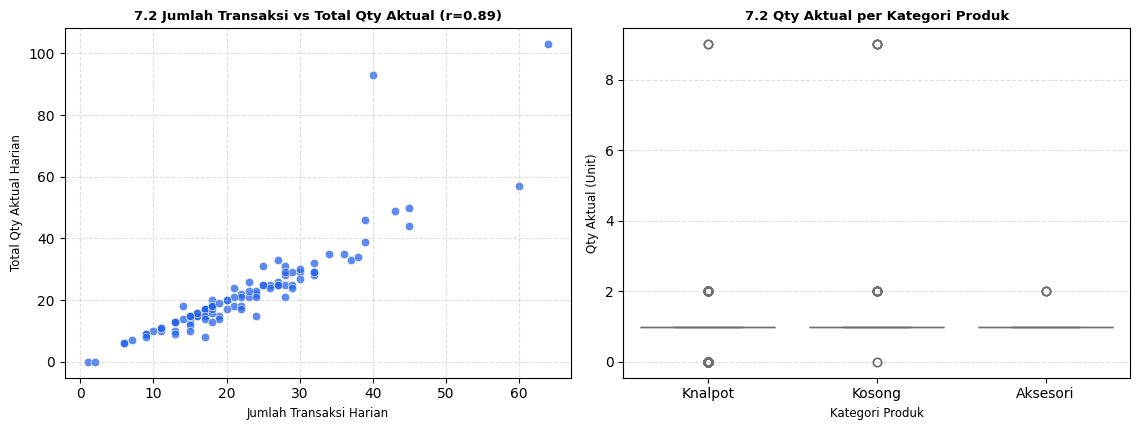

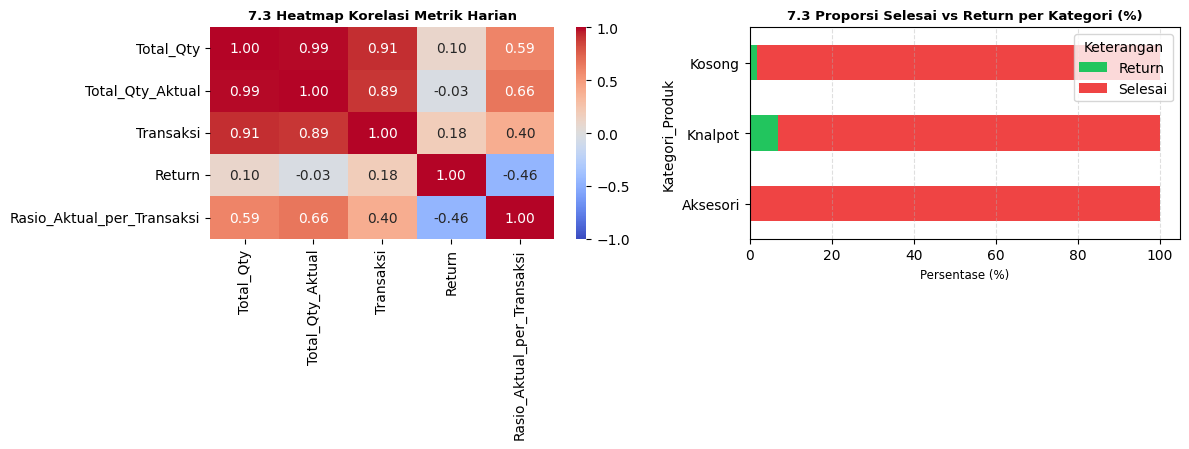

In [44]:
print("=== BAB 7: VISUALISASI HUBUNGAN DATA ===")

# 7.1 Analisis Univariat Kategorikal (Barplot / Countplot)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.3), dpi=100)

kat_counts = df['Kategori_Produk'].value_counts()
sns.barplot(x=kat_counts.values, y=kat_counts.index, ax=ax1, palette='viridis')
ax1.set_title("7.1 Distribusi Kategori Produk", fontweight='bold', fontsize=9.5)
ax1.set_xlabel("Jumlah Transaksi", fontsize=8.5)
ax1.grid(axis='x', linestyle='--', alpha=0.4)

ket_counts = df['Keterangan'].fillna('Kosong').value_counts()
sns.barplot(x=ket_counts.values, y=ket_counts.index, ax=ax2, palette='magma')
ax2.set_title("7.1 Distribusi Keterangan Transaksi", fontweight='bold', fontsize=9.5)
ax2.set_xlabel("Jumlah Transaksi", fontsize=8.5)
ax2.grid(axis='x', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

# 7.2 Bivariat: Numerik vs Numerik (Scatterplot) & Kategorikal vs Numerik (Boxplot)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.4), dpi=100)

r_val = daily['Transaksi'].corr(daily['Total_Qty_Aktual'])
sns.scatterplot(data=daily, x='Transaksi', y='Total_Qty_Aktual', ax=ax1, alpha=0.75, color='#2563eb')
ax1.set_title(f"7.2 Jumlah Transaksi vs Total Qty Aktual (r={r_val:.2f})", fontweight='bold', fontsize=9.5)
ax1.set_xlabel("Jumlah Transaksi Harian", fontsize=8.5)
ax1.set_ylabel("Total Qty Aktual Harian", fontsize=8.5)
ax1.grid(True, linestyle='--', alpha=0.4)

sns.boxplot(data=df, x='Kategori_Produk', y='Qty_Aktual_num', ax=ax2, palette='pastel')
ax2.set_title("7.2 Qty Aktual per Kategori Produk", fontweight='bold', fontsize=9.5)
ax2.set_xlabel("Kategori Produk", fontsize=8.5)
ax2.set_ylabel("Qty Aktual (Unit)", fontsize=8.5)
ax2.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

# 7.3 Heatmap Korelasi Numerik Harian & Stacked Bar Komposisi Return per Kategori
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.6), dpi=100)

num_daily_cols = ['Total_Qty', 'Total_Qty_Aktual', 'Transaksi', 'Return', 'Rasio_Aktual_per_Transaksi']
corr_daily = daily[num_daily_cols].corr()
sns.heatmap(corr_daily, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax1)
ax1.set_title("7.3 Heatmap Korelasi Metrik Harian", fontweight='bold', fontsize=9.5)

ct_kat = pd.crosstab(df['Kategori_Produk'], df['Keterangan'], normalize='index') * 100
ct_kat.plot(kind='barh', stacked=True, ax=ax2, color=['#22c55e', '#ef4444'])
ax2.set_title("7.3 Proporsi Selesai vs Return per Kategori (%)", fontweight='bold', fontsize=9.5)
ax2.set_xlabel("Persentase (%)", fontsize=8.5)
ax2.grid(axis='x', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

=== BAB 8: DETEKSI & EVALUASI PENCILAN (OUTLIER) ===


,Variabel,Q1,Q3,IQR,Batas Bawah,Batas Atas,Outlier IQR,Outlier |Z|>3
0,Total Qty Harian,16.00,28.00,12.0,-2.0,46.0,5 (4.72%),2
1,Total Qty Aktual Harian,14.25,25.75,11.5,-3.0,43.0,7 (6.60%),2


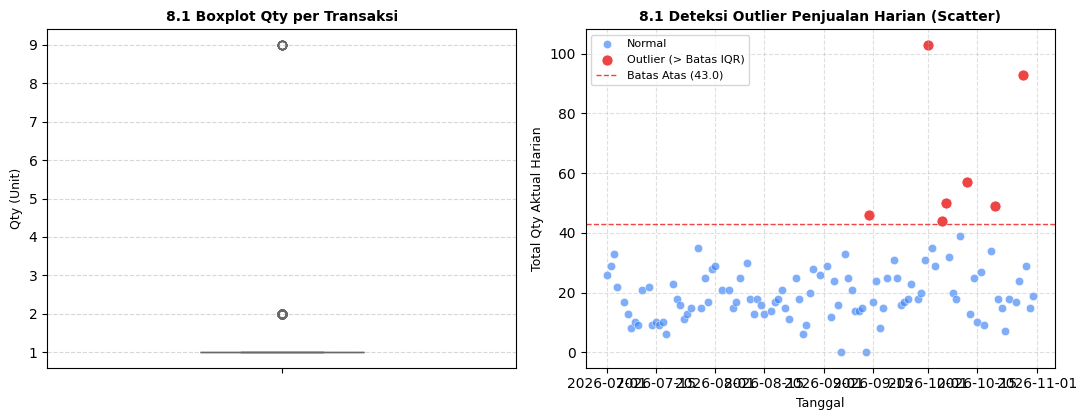

,Tanggal,Total_Qty,Total_Qty_Aktual,Transaksi,Return
79,01/10/2026,105.0,103.0,64,2
102,28/10/2026,93.0,93.0,40,0
88,12/10/2026,60.0,57.0,60,3
83,06/10/2026,51.0,50.0,45,1
95,20/10/2026,50.0,49.0,43,1
64,14/09/2026,46.0,46.0,39,0
82,05/10/2026,45.0,44.0,45,1


In [40]:
print("=== BAB 8: DETEKSI & EVALUASI PENCILAN (OUTLIER) ===")

# 8.1 Perhitungan Batas IQR & Z-Score
def hitung_iqr_z(series, nama):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outliers_iqr = series[(series < lower) | (series > upper)]
    z_scores = np.abs((series - series.mean()) / series.std(ddof=0)) if series.std(ddof=0) > 0 else pd.Series(0, index=series.index)
    outliers_z = series[z_scores > 3]
    return {
        'Variabel': nama,
        'Q1': q1,
        'Q3': q3,
        'IQR': iqr,
        'Batas Bawah': lower,
        'Batas Atas': upper,
        'Outlier IQR': f"{len(outliers_iqr)} ({len(outliers_iqr)/len(series)*100:.2f}%)",
        'Outlier |Z|>3': len(outliers_z)
    }

tab_7_1 = pd.DataFrame([
    hitung_iqr_z(daily['Total_Qty'], 'Total Qty Harian'),
    hitung_iqr_z(daily['Total_Qty_Aktual'], 'Total Qty Aktual Harian')
])
display(tab_7_1.round(2))

# Visualisasi Bab 8: Boxplot & Scatter Outlier Harian
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.3), dpi=100)

sns.boxplot(y=df['Qty_num'], ax=ax1, color='#60a5fa', width=0.35)
ax1.set_title('8.1 Boxplot Qty per Transaksi', fontweight='bold', fontsize=10)
ax1.set_ylabel('Qty (Unit)', fontsize=9)
ax1.grid(axis='y', linestyle='--', alpha=0.5)

batas_atas_akt = tab_7_1.loc[1, 'Batas Atas']
is_out = daily['Total_Qty_Aktual'] > batas_atas_akt
sns.scatterplot(data=daily[~is_out], x='Tanggal_dt', y='Total_Qty_Aktual', ax=ax2, color='#3b82f6', alpha=0.65, label='Normal')
sns.scatterplot(data=daily[is_out], x='Tanggal_dt', y='Total_Qty_Aktual', ax=ax2, color='#ef4444', s=65, label='Outlier (> Batas IQR)')
ax2.axhline(batas_atas_akt, color='#ef4444', linestyle='--', linewidth=1, label=f'Batas Atas ({batas_atas_akt:.1f})')
ax2.set_title('8.1 Deteksi Outlier Penjualan Harian (Scatter)', fontweight='bold', fontsize=10)
ax2.set_xlabel('Tanggal', fontsize=9)
ax2.set_ylabel('Total Qty Aktual Harian', fontsize=9)
ax2.legend(fontsize=8)
ax2.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

# 8.2 Daftar Tanggal Outlier Puncak
outlier_dates = daily[daily['Total_Qty_Aktual'] > batas_atas_akt][['Tanggal_dt', 'Total_Qty', 'Total_Qty_Aktual', 'Transaksi', 'Return']].copy()
outlier_dates['Tanggal'] = outlier_dates['Tanggal_dt'].dt.strftime('%d/%m/%Y')
display(outlier_dates[['Tanggal', 'Total_Qty', 'Total_Qty_Aktual', 'Transaksi', 'Return']].sort_values(by='Total_Qty_Aktual', ascending=False))

=== BAB 9: EVALUASI BASELINE & RINGKASAN TEMUAN ===
Rata-rata Prediktor Baseline Latih: 18.62 unit/hari
Target Baseline MAE Oktober:        16.25 unit
Target Baseline RMSE Oktober:       26.17 unit


,Platform_Kanal_Asal,Total_Transaksi,Jumlah_Return,Rasio_Return (%)
3,Shopee,1449,74,5.11
4,TikTok,682,64,9.38
5,WhatsApp,124,0,0.00
1,Kosong,54,0,0.00
0,Ekspedisi (J&T/Ninja),13,13,100.00
2,Return_Tanpa_Kanal,2,2,100.00


/tmp/ipykernel_5259/880002833.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=ret_sorted['Rasio_Return (%)'], y=ret_sorted['Platform_Kanal_Asal'], ax=ax2, palette='Reds')


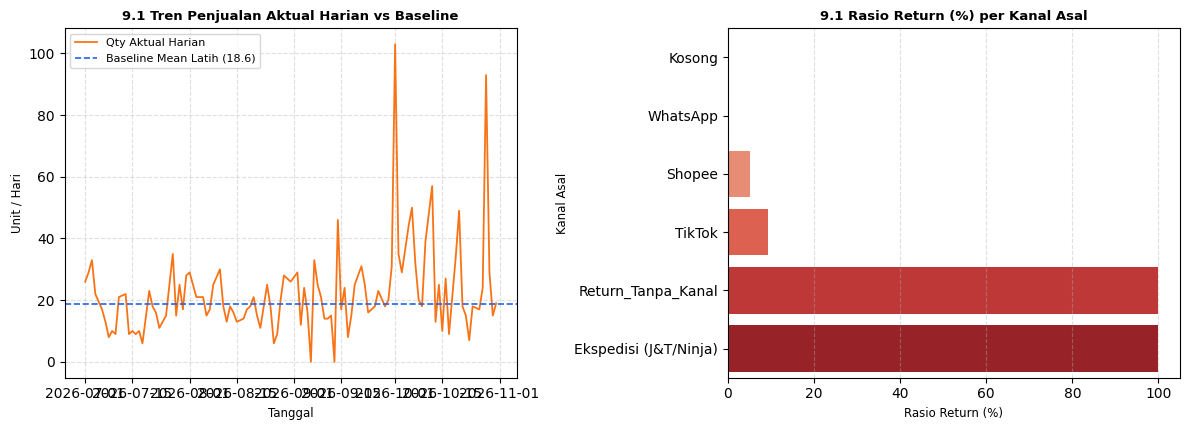

In [41]:
print("=== BAB 9: EVALUASI BASELINE & RINGKASAN TEMUAN ===")

# 9.1 Evaluasi Baseline Regresi Harian (Data Uji Oktober)
train_daily = daily[daily['Tanggal_dt'] < '2026-10-01']
test_daily = daily[daily['Tanggal_dt'] >= '2026-10-01']

mean_train = train_daily['Total_Qty_Aktual'].mean()
y_test_true = test_daily['Total_Qty_Aktual']

mae_baseline = np.mean(np.abs(y_test_true - mean_train))
rmse_baseline = np.sqrt(np.mean((y_test_true - mean_train)**2))

print(f"Rata-rata Prediktor Baseline Latih: {mean_train:.2f} unit/hari")
print(f"Target Baseline MAE Oktober:        {mae_baseline:.2f} unit")
print(f"Target Baseline RMSE Oktober:       {rmse_baseline:.2f} unit")

# 9.2 Sebaran Kelas Target Return per Kanal Asal
return_summary = df.groupby('Platform_Kanal_Asal').agg(
    Total_Transaksi=('No', 'count'),
    Jumlah_Return=('Keterangan', lambda x: (x == 'Return').sum())
).reset_index()
return_summary['Rasio_Return (%)'] = (return_summary['Jumlah_Return'] / return_summary['Total_Transaksi'] * 100).round(2)
display(return_summary.sort_values(by='Total_Transaksi', ascending=False))

# Visualisasi Bab 9: Tren Penjualan Harian & Rasio Return per Kanal
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.4), dpi=100)

ax1.plot(daily['Tanggal_dt'], daily['Total_Qty_Aktual'], color='#f97316', linewidth=1.3, label='Qty Aktual Harian')
ax1.axhline(mean_train, color='#2563eb', linestyle='--', linewidth=1.2, label=f'Baseline Mean Latih ({mean_train:.1f})')
ax1.set_title("9.1 Tren Penjualan Aktual Harian vs Baseline", fontweight='bold', fontsize=9.5)
ax1.set_xlabel("Tanggal", fontsize=8.5)
ax1.set_ylabel("Unit / Hari", fontsize=8.5)
ax1.legend(fontsize=8)
ax1.grid(True, linestyle='--', alpha=0.4)

ret_sorted = return_summary.sort_values(by='Rasio_Return (%)', ascending=True)
sns.barplot(x=ret_sorted['Rasio_Return (%)'], y=ret_sorted['Platform_Kanal_Asal'], ax=ax2, palette='Reds')
ax2.set_title("9.1 Rasio Return (%) per Kanal Asal", fontweight='bold', fontsize=9.5)
ax2.set_xlabel("Rasio Return (%)", fontsize=8.5)
ax2.set_ylabel("Kanal Asal", fontsize=8.5)
ax2.grid(axis='x', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()